In [22]:
%matplotlib widget
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import tqdm.auto as tqdm
from scipy.interpolate import interp1d


In [23]:
gitt = pl.read_csv("data/gitt_results.csv").with_columns(pl.lit("gitt").alias("source"))
ici = (
    pl.read_csv("data/ici_results.csv")
    .filter(pl.col("File / 1").str.contains("001-ici"))
    .group_by("Direction / 1", "State of Charge / 1")
    .agg(
        pl.col("Open-circuit voltage / V").mean().alias("Open-circuit voltage / V"),
        pl.col("R0 / Ohm").mean().alias("R0 / Ohm"),
        pl.col("R1 / Ohm").mean().alias("R1 / Ohm"),
        pl.col("Tau1 / s").mean().alias("Tau1 / s"),
    )
    .with_columns(pl.lit("ici").alias("source"))
)

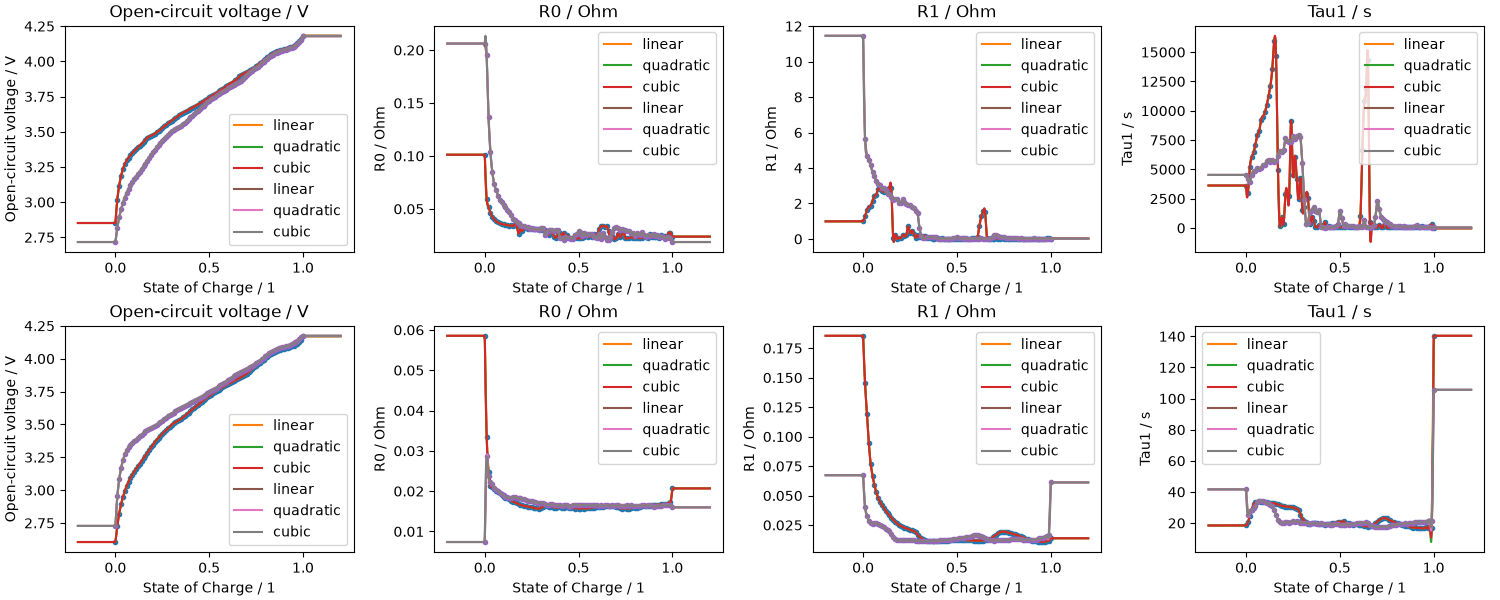

In [24]:
kinds = ["linear", "quadratic", "cubic"]
cols = ["Open-circuit voltage / V", "R0 / Ohm", "R1 / Ohm", "Tau1 / s"]


fig, axs = plt.subplots(2, len(cols), figsize=(15, 6), constrained_layout=True)
for i, data in enumerate([gitt, ici]):
    for j, col in enumerate(cols):
        ax = axs[i, j]

        for df in data.partition_by("Direction / 1"):
            df = df.sort("State of Charge / 1")
            x, y = df.select("State of Charge / 1", col).to_numpy().T
            z = np.linspace(x.min() - 0.2, x.max() + 0.2, 1000)
            (pl,) = ax.plot(x, y, marker=".", ls="none")
            for kind in kinds:
                lut = interp1d(
                    x, y, kind=kind, fill_value=(y[0], y[-1]), bounds_error=False
                )
                ax.plot(z, lut(z), label=f"{kind}")

        ax.set_title(col)
        ax.set_xlabel("State of Charge / 1")
        ax.set_ylabel(col)
        ax.legend()

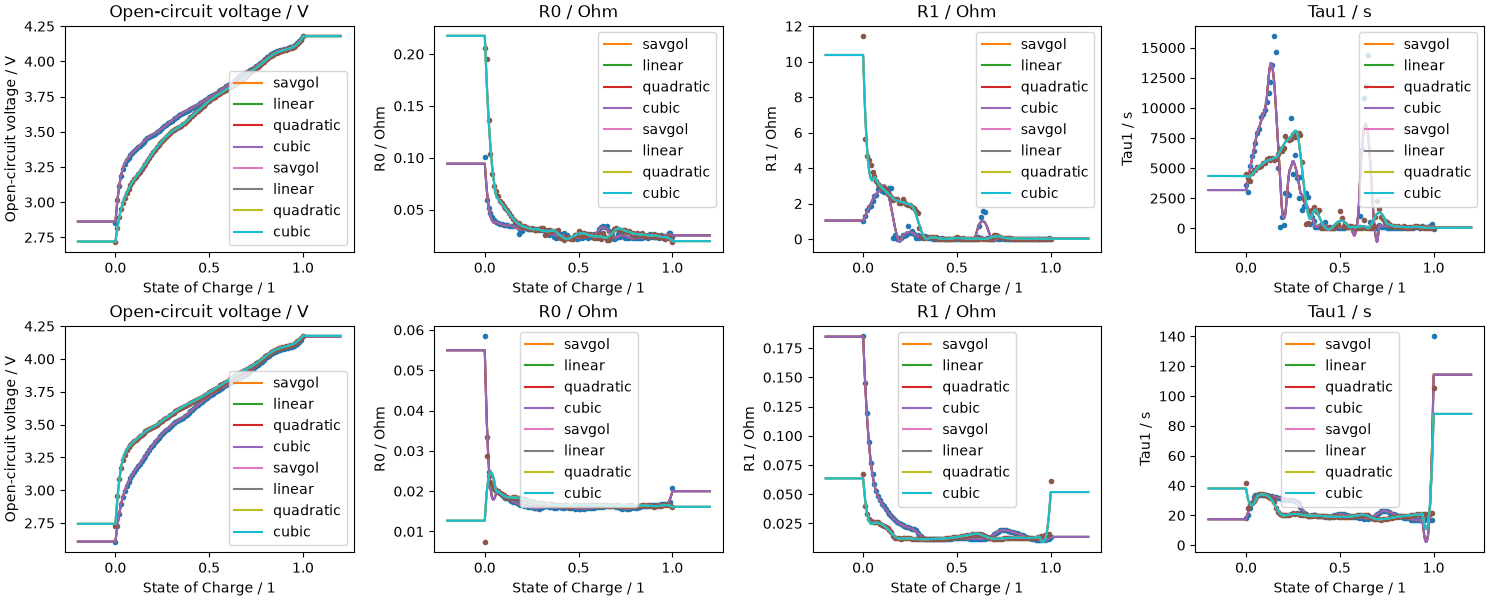

In [25]:
from scipy.signal import savgol_filter

kinds = ["linear", "quadratic", "cubic"]
cols = ["Open-circuit voltage / V", "R0 / Ohm", "R1 / Ohm", "Tau1 / s"]


fig, axs = plt.subplots(2, len(cols), figsize=(15, 6), constrained_layout=True)
for i, data in enumerate([gitt, ici]):
    for j, col in enumerate(cols):
        ax = axs[i, j]

        for df in data.partition_by("Direction / 1"):
            df = df.sort("State of Charge / 1")
            x, y = df.select("State of Charge / 1", col).to_numpy().T
            yf = savgol_filter(y, 11, 3)
            z = np.linspace(x.min() - 0.2, x.max() + 0.2, 1000)
            (pl,) = ax.plot(x, y, marker=".", ls="none")
            ax.plot(x, yf, label="savgol")
            for kind in kinds:
                lut = interp1d(
                    x, yf, kind=kind, fill_value=(yf[0], yf[-1]), bounds_error=False
                )
                ax.plot(z, lut(z), label=f"{kind}")

        ax.set_title(col)
        ax.set_xlabel("State of Charge / 1")
        ax.set_ylabel(col)
        ax.legend()